In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from europa_eutectic.gaia_sim import GaiaSim
from europa_eutectic.util import colors

AUX_BASE = Path("../../data")
shell_visc_sims = [json_path for json_path in Path(AUX_BASE / "shell_visc").glob("*.json")]
shell_complex_rheo_sims = [json_path for json_path in Path(AUX_BASE / "shell_complex_rheo").glob("*.json")]
constK_varA_sims = [json_path for json_path in Path(AUX_BASE / "shell_thermal_cond_expan" / "constK_varA").glob("*.json")]
varK_constA_sims= [json_path for json_path in Path(AUX_BASE / "shell_thermal_cond_expan" / "varK_constA").glob("*.json")]
varK_varA_sims= [json_path for json_path in Path(AUX_BASE / "shell_thermal_cond_expan" / "varK_varA").glob("*.json")]
shell_tidal_sims = [json_path for json_path in Path(AUX_BASE / "shell_tidal").glob("*.json")]

base_cmap = sns.color_palette("icy_moon_2", as_cmap = True) # My custom colormap
inferno = sns.color_palette("inferno", as_cmap = True)

In [2]:
shell_visc_sims

[PosixPath('../../../../../auxillary/shell_visc/Europa_D20km_eta1e+13_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D20km_eta1e+14_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D20km_eta1e+15_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D30km_eta1e+13_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D30km_eta1e+15_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D40km_eta1e+13_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D40km_eta1e+15_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D50km_eta1e+13_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D40km_eta1e+14_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D50km_eta1e+14_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D60km_eta1e+13_data.json'),
 PosixPath('../../../../../auxillary/shell_visc/Europa_D60km_eta1e+14_data.json'),
 Pos

In [12]:
# left end member - 10^12, D50, lateral detectability 100%
left_sim_path = Path("../../../../../auxillary/shell_visc/Europa_D20km_eta1e+12_data.json")
left_sim = GaiaSim.load_from_json(left_sim_path)

# middle end member - 10^14, D50, detectability ~50%
middle_sim_path = Path("../../../../../auxillary/shell_visc/Europa_D50km_eta1e+14_data.json")
middle_sim = GaiaSim.load_from_json(middle_sim_path)

# right end member - Lateral Detectability 12% - 60km, 10^15
right_sim_path = Path("../../../../../auxillary/shell_visc/Europa_D60km_eta1e+15_data.json")
right_sim = GaiaSim.load_from_json(right_sim_path)

In [9]:
def build_interface_frame(sim):
    records = []

    attenuation_label_map = {
        "Low Loss": "Depth to 100 dB (Low Loss)",
        "High Loss": "Depth to 100 dB (High Loss)",
    }

    eutectic_label_map = {
        237.15: "Depth to 237.15 K (Zolotov)",
        252.05: "Depth to 252.05 K (NaCl)",
    }

    for attenuation_interface in sim.attenuation_interfaces:
        label = attenuation_label_map.get(attenuation_interface.attenuation_model)
        if label is None:
            continue

        x = attenuation_interface.distance_along_equator / 1000
        y = attenuation_interface.depth_to_attenuation_limit / 1000

        for xi, yi in zip(x, y):
            records.append(
                {
                    "Distance Along Equator (km)": xi,
                    "Depth (km)": yi,
                    "Interface": label,
                }
            )

    for eutectic in sim.eutectics:
        label = eutectic_label_map.get(round(eutectic.eutectic_temperature, 2))
        if label is None:
            continue

        x = eutectic.distance_along_equator / 1000
        y = eutectic.depth_to_eutectic / 1000

        for xi, yi in zip(x, y):
            records.append(
                {
                    "Distance Along Equator (km)": xi,
                    "Depth (km)": yi,
                    "Interface": label,
                }
            )

    return pd.DataFrame(records)

In [10]:
simulations = [
    ("Left End Member", left_sim),
    ("Middle End Member", middle_sim),
    ("Right End Member", right_sim),
]

palette = {
    "Depth to 237.15 K (Zolotov)": base_cmap(0.25),
    "Depth to 252.05 K (NaCl)": base_cmap(0.75),
    "Depth to 100 dB (Low Loss)": inferno(0.35),
    "Depth to 100 dB (High Loss)": inferno(0.8),
}

top_interfaces = [
    "Depth to 237.15 K (Zolotov)",
    "Depth to 100 dB (Low Loss)",
    "Depth to 100 dB (High Loss)",
]

bottom_interfaces = [
    "Depth to 252.05 K (NaCl)",
    "Depth to 100 dB (Low Loss)",
    "Depth to 100 dB (High Loss)",
]

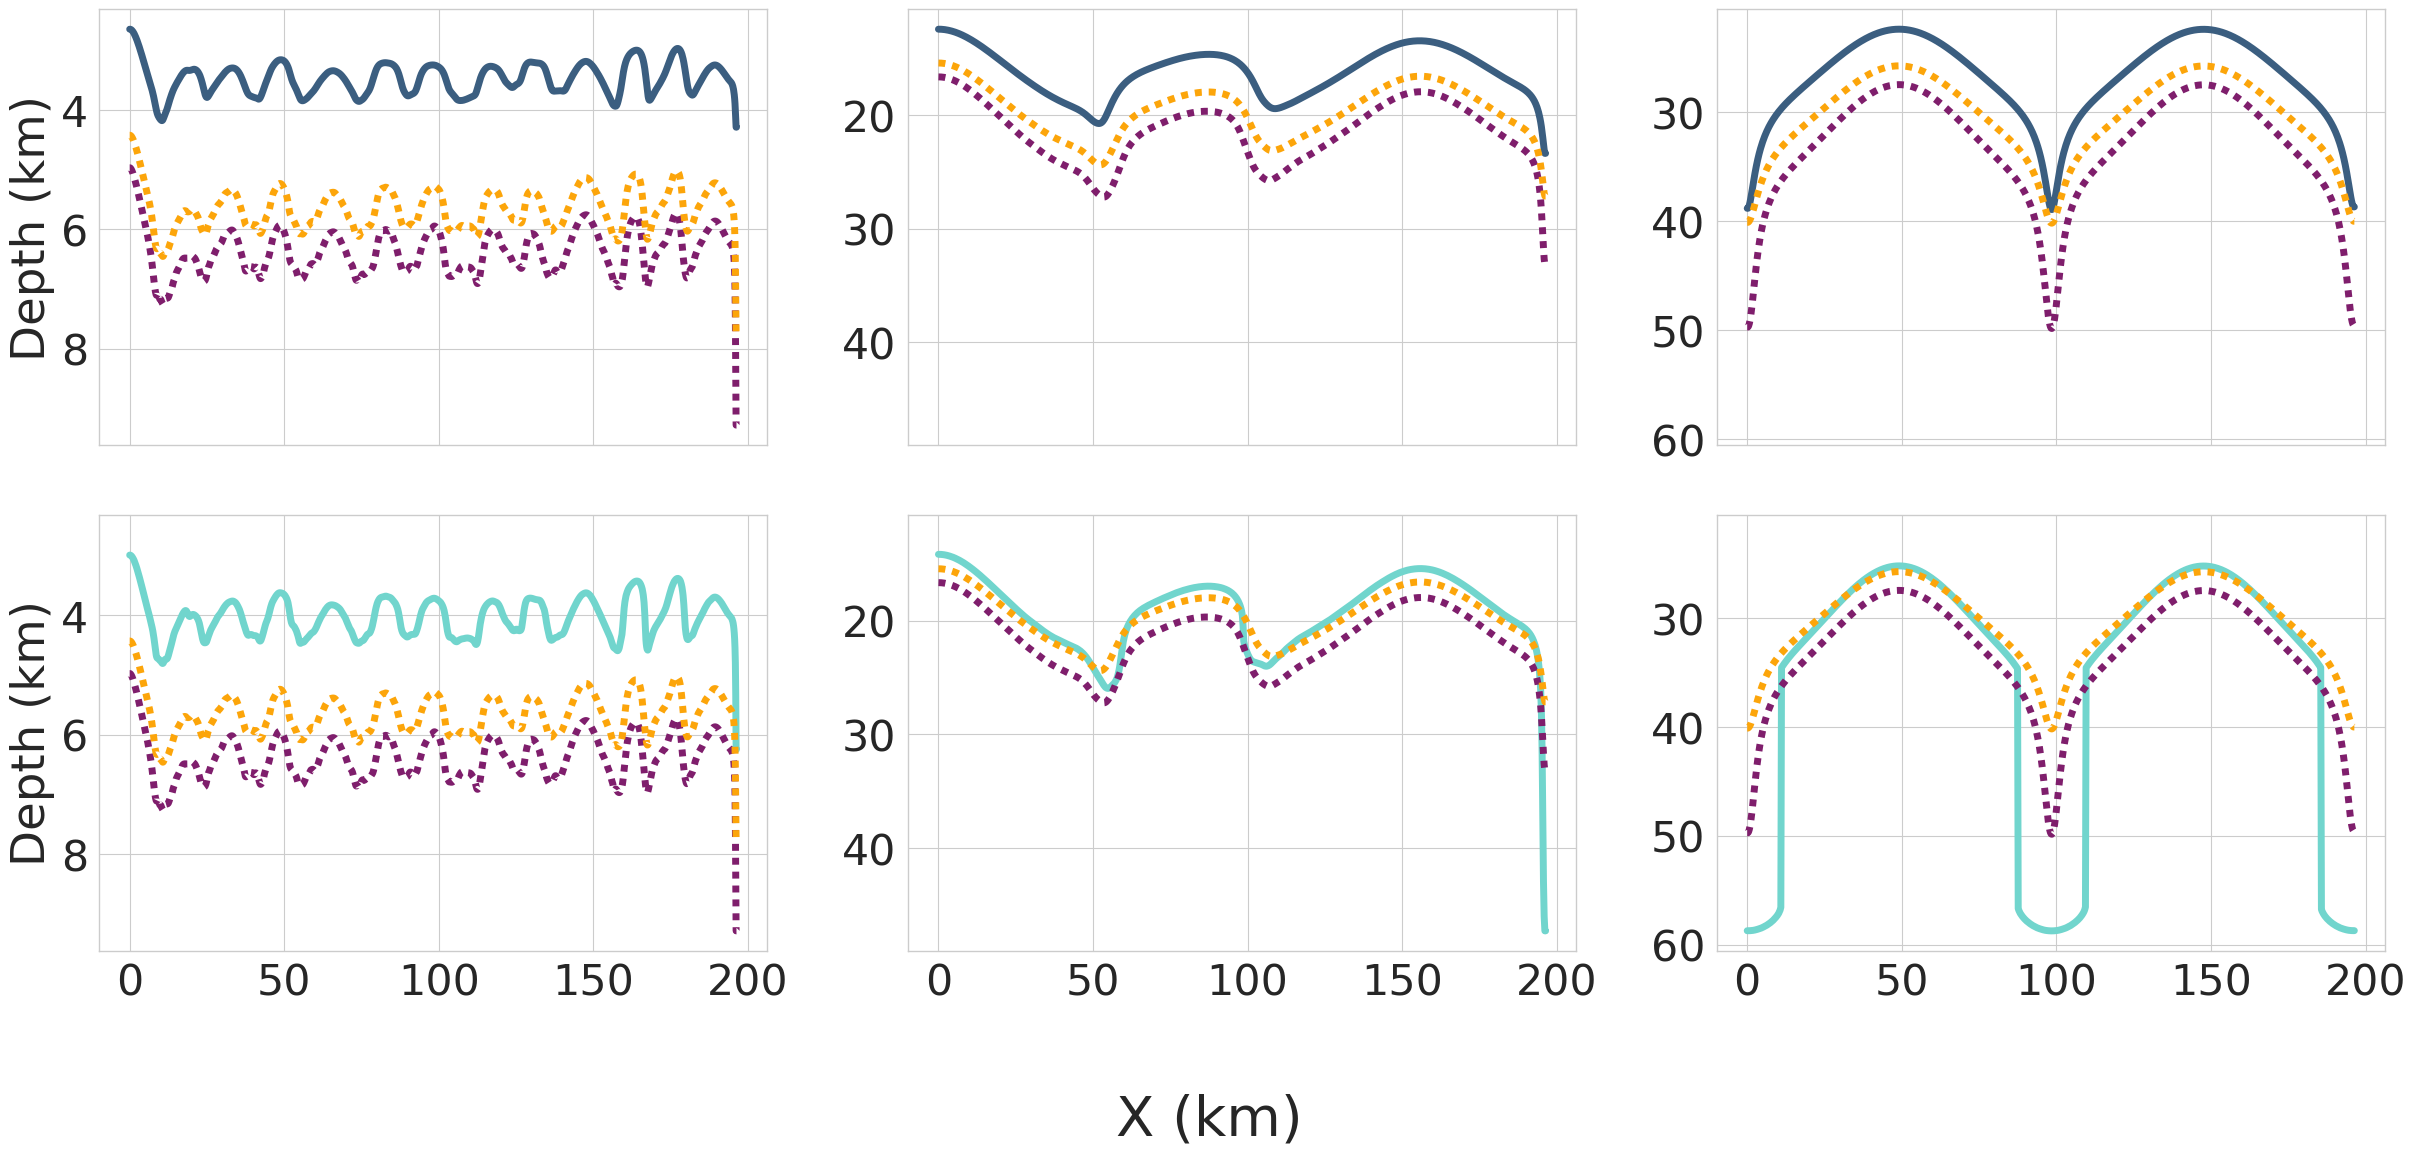

In [19]:
sns.set_theme(style="whitegrid", context="paper", font_scale=3.5)
fig, axes = plt.subplots(2, 3, figsize=(25, 12), sharex=True, sharey='col')

for column_index, (_, sim) in enumerate(simulations):
    plot_df = build_interface_frame(sim)
    plot_df["Line Style"] = np.where(
        plot_df["Interface"].str.contains("100 dB", regex=False),
        "Attenuation",
        "Eutectic"
    )

    top_df = plot_df[plot_df["Interface"].isin(top_interfaces)]
    sns.lineplot(
        data=top_df,
        x="Distance Along Equator (km)",
        y="Depth (km)",
        hue="Interface",
        hue_order=top_interfaces,
        palette=palette,
        style="Line Style",
        style_order=["Eutectic", "Attenuation"],
        dashes={"Eutectic": "", "Attenuation": (1, 1)},
        legend=False,
        linewidth=5,
        ax=axes[0, column_index],
    )

    bottom_df = plot_df[plot_df["Interface"].isin(bottom_interfaces)]
    sns.lineplot(
        data=bottom_df,
        x="Distance Along Equator (km)",
        y="Depth (km)",
        hue="Interface",
        hue_order=bottom_interfaces,
        palette=palette,
        style="Line Style",
        style_order=["Eutectic", "Attenuation"],
        dashes={"Eutectic": "", "Attenuation": (1, 1)},
        linewidth=5,
        legend=False,
        ax=axes[1, column_index],
    )

for row_index in range(2):
    for column_index in range(3):
        axes[row_index, column_index].set_title("")
        axes[row_index, column_index].set_xlabel("")
        axes[row_index, column_index].set_ylabel("")

for column_index in range(3):
    axes[0, column_index].invert_yaxis()

axes[0, 0].set_ylabel("Depth (km)")
axes[1, 0].set_ylabel("Depth (km)")
fig.supxlabel("X (km)")
plt.tight_layout()
plt.savefig("figure3_detectability_demo.png", bbox_inches='tight', transparent = True, dpi = 300)
plt.show()

# understanding weird calculations

In [27]:
shell_visc_14_sims  = [GaiaSim.load_from_json(sim_path) for sim_path in shell_visc_sims if "eta1e+14" in sim_path.name]
shell_visc_15_sims  = [GaiaSim.load_from_json(sim_path) for sim_path in shell_visc_sims if "eta1e+15" in sim_path.name]

varK_constA_sims = [GaiaSim.load_from_json(sim_path) for sim_path in varK_constA_sims]
constK_varA_sims = [GaiaSim.load_from_json(sim_path) for sim_path in constK_varA_sims]
varK_varA_sims = [GaiaSim.load_from_json(sim_path) for sim_path in varK_varA_sims]
complex_rheo_sims = [GaiaSim.load_from_json(sim_path) for sim_path in shell_complex_rheo_sims]

reg2_109_RR0.987186_P0.02.grid  PATH /plp_scr2/byrn_wi/europa_eutectic_constrain/Europa_D20km_eta1e+14/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws/7/byrn_wi-europa_eutectic/Europa_D40km_eta1e+14/.
reg2_186_RR0.980779_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_30km_eta1e+14/.
reg2_79_RR0.987186_P0.02.grid  PATH /plp_scr2/byrn_wi/europa_eutectic_constrain/Europa_D20km_eta1e+15/.
reg2_141_RR0.980779_P0.02.grid  PATH /plp_scr2/byrn_wi/europa_eutectic_constrain/Europa_D30km_eta1e+15/.
reg2_210_RR0.974372_P0.02.grid  PATH /plp_scr2/byrn_wi/europa_eutectic_constrain/Europa_D40km_eta1e+15/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_50km_eta1e+15/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_constA/Europa_D40km_eta1e+13/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_constA/Europa_D50km_eta1e+13/.
reg2_270_RR0.961558_P0.02.grid  PATH /